# 1회차: Statcast의 역사와 측정 방식

- **파트**: Part A. Statcast
- **사용 피처**: game_year, game_date, 연도별 컬럼 존재 여부(비결측률)
- **코드 패턴**: P1(구조·품질 점검), P6(검증·대조)

**실행 검증 정보**

| 항목 | 내용 |
|---|---|
| 상태 | 최종본 |
| 실행 날짜 | 2026-10-23 |
| 데이터 | Baseball Savant Statcast Search(pybaseball `statcast`), 2008~2026년 매년 8월 14~16일, 투구 226,667개 |
| 데이터 내려받은 날짜 | 2026-10-23 |
| pybaseball | 2.2.7 |
| Python | 3.13.7 |
| 통과한 게이트 | G1, G2, G3, G4, G5, G6, G8, G9, G10, G11 (G7은 ML 회차가 아니어서 해당 없음) |

## 이번 회차에서 배울 것
- Statcast 이전(PITCHf/x)부터 Statcast, Hawk-Eye까지 MLB 추적 시스템이 바뀐 시기를 공식 문서로 정리합니다.
- pybaseball로 받은 데이터에서 "컬럼이 있다"와 "값이 있다"가 다르다는 것을 확인합니다.
- 연도별 비결측률로 각 컬럼이 언제부터 채워지는지 직접 확인하고, 문서의 연표와 대조합니다.

## 1. 이론

### 1-1. 이번 회차에서 쓰는 컬럼의 정의
Baseball Savant의 Statcast Search CSV 문서[1]에 적힌 정의입니다.

| 컬럼 | 문서의 정의 |
|---|---|
| `game_date` | Date of the Game. |
| `game_year` | Year game took place. |
| `spin_dir`, `spin_rate_deprecated`, `break_angle_deprecated`, `break_length_deprecated`, `tfs_deprecated`, `tfs_zulu_deprecated`, `umpire` | Deprecated field from the old tracking system. (예전 추적 시스템의 폐기된 필드) |
| `sv_id` | Non-unique Id of play event per game. |
| `launch_speed`, `launch_angle` | Statcast가 추적한 타구 속도와 발사각. 직접 추적되지 않은 일부 타구에는 추정값이 들어갑니다. |

- 폐기 필드, `sv_id`, 타구 추정값에 대한 설명은 단일 출처(Savant CSV 문서)입니다.
- 문서의 컬럼 이름과 pybaseball 출력의 컬럼 이름은 다를 수 있습니다. 아래 실습에서 실제 이름을 기준으로 대조합니다.

### 1-2. 측정 방식: 추적 시스템의 연표

| 시기 | 내용 | 출처 |
|---|---|---|
| 2006 | 포스트시즌에 처음으로 실시간 자동 구종 분류 시스템을 도입했습니다. | 단일 출처([3]) |
| 2008 | 정규시즌 시작부터 30개 구장 전체에 투구 추적 장비가 설치되어, 구종과 구속이 리그 전체에서 기록되기 시작했습니다(pitch-tracking era). | [2], [3] |
| 2008 ~ Statcast 도입 전 | 투구 추적 데이터는 PITCHf/x가 제공했습니다. | 단일 출처([3]) |
| 2014 | Statcast를 일부 구장에서 시범 운영했습니다. | 단일 출처([2]) |
| 2015 | Statcast가 30개 구장 전체에 설치되었습니다. | [2], [3] |
| 2008 ~ 2016 | `release_speed`(구속)는 PITCHf/x 값을 릴리스 지점 기준으로 보정한 것이고, 2017년부터는 Statcast 값입니다. | [1], [3] |
| 2015 ~ 2019 | Statcast는 카메라와 레이더를 조합해 측정했습니다. 투구 추적은 Trackman 레이더가 맡았습니다. | [2], [3], [4] |
| 2020 ~ | Hawk-Eye 카메라 시스템으로 바뀌었습니다. 구장마다 카메라 12대를 두고, 고속 카메라 5대는 투구(와 이후 배트) 추적, 7대는 선수와 타구 추적을 맡습니다. | [2], [4] |
| 2020 ~ | 추적되는 타구의 비율이 이전 시스템의 약 89%에서 약 99%로 올라갔습니다. | [2], [4] |
| 2023 | 고속 카메라가 초당 100프레임에서 300프레임으로 업그레이드되었습니다. | 단일 출처([2]) |
| 2023 후반기 ~ | 배트 트래킹(스윙 속도 등) 데이터가 제공됩니다. | [2], [5] |
| 2026 ~ | `plate_x`, `plate_z`의 기준이 홈플레이트 앞면에서 가운데로 바뀌고, `sz_top`, `sz_bot`은 ABS 기준 스트라이크존 값이 됩니다. | 단일 출처([1]) |

2026년 정의 변경은 5회차, 14회차, 15회차에서 자세히 다룹니다.

### 1-3. 왜 중요한가
- 한 컬럼의 값은 그 해에 어떤 추적 시스템이 돌고 있었는지에 따라 **있기도 하고 없기도** 합니다. 예를 들어 타구 속도(`launch_speed`)는 Statcast가 전 구장에 설치되기 전 연도에는 값이 없습니다(2-8에서 확인).
- 값이 채워져 있어도 **측정 주체나 정의가 바뀐 경우**가 있습니다(`release_speed`의 2017년 전환, 2026년 `plate_x`·`sz_top` 정의 변경). 연도 비교를 하기 전에 이 시기를 알아야 합니다.
- 그래서 이 스터디의 다른 회차에서 연도를 비교할 때는 이 회차에서 확인한 "컬럼별 시작 연도"를 기준으로 기간을 고릅니다.

## 2. 코드 실습

### 2-1. 경로 설정
노트북을 어느 폴더에서 열어도 레포 루트를 찾도록 `.git` 폴더를 기준으로 합니다.

In [1]:
from pathlib import Path

def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for d in [start, *start.parents]:
        if (d / '.git').exists():
            return d
    raise RuntimeError('레포 루트(.git)를 찾지 못했습니다.')

ROOT = find_repo_root()
LESSON_DIR = ROOT / 'data' / '01_history'
LESSON_DIR.mkdir(parents=True, exist_ok=True)

### 2-2. 라이브러리와 실행 환경
pybaseball 2.2.7은 내부에서 `DataFrame.convert_dtypes(convert_string=False)`를 호출하는데, pandas 3.1.0은 이 인자가 앞으로의 버전에서 없어진다는 `Pandas4Warning`(`DeprecationWarning`의 하위 클래스)을 냅니다. 값에는 영향이 없는 경고이므로, 경고 설정이 바뀌어도 나타나지 않도록 이 메시지 하나만 숨깁니다.

In [2]:
import sys
import io
import warnings
import contextlib

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pybaseball
from importlib.metadata import version
from pybaseball import statcast

warnings.filterwarnings('ignore', message='The convert_string keyword', category=DeprecationWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

print('python    ', sys.version.split()[0])
print('pybaseball', version('pybaseball'))
print('pandas    ', pd.__version__)
print('matplotlib', matplotlib.__version__)
print('seaborn   ', sns.__version__)

python     3.13.7
pybaseball 2.2.7
pandas     3.1.0
matplotlib 3.11.2
seaborn    0.13.2


### 2-3. 데이터 범위: 매년 같은 시기 사흘(8월 14~16일)
- 연도를 비교하므로 모든 해의 기간을 같은 시기로 맞춥니다.
- 2008~2026년 모든 해에 정규시즌 경기가 있는 시기로 8월 중순을 고릅니다. 실제로 모든 해에 경기가 받아졌는지는 2-5에서 확인합니다.
- 데이터는 pybaseball의 `statcast` 함수[6]로 받습니다.
- 이 회차의 주제가 "어떤 컬럼이 언제부터 채워지는가"이므로, 이번에는 컬럼을 고르지 않고 전체 컬럼을 받습니다.
- 연도별로 나눠 받아 `data/01_history/`에 Parquet으로 캐싱합니다. 파일이 이미 있으면 다시 받지 않습니다.

In [3]:
YEARS = list(range(2008, 2027))
START_MD, END_MD = '08-14', '08-16'

def load_year(year):
    """해당 연도 8월 14~16일 Statcast 데이터를 캐시에서 읽고, 없으면 받아서 저장합니다."""
    path = LESSON_DIR / f'statcast_{year}_{START_MD}_{END_MD}.parquet'
    if not path.exists():
        with contextlib.redirect_stderr(io.StringIO()):  # 진행 막대만 숨깁니다. 예외는 그대로 발생합니다.
            df = statcast(start_dt=f'{year}-{START_MD}', end_dt=f'{year}-{END_MD}', verbose=False)
        if df.empty:
            raise RuntimeError(f'{year}년 데이터를 받지 못했습니다. 예시 데이터로 대체하지 않고 중단합니다.')
        df.to_parquet(path, index=False)
    return pd.read_parquet(path), path

frames, columns_by_year, fetched_on = [], {}, {}
for y in YEARS:
    d, p = load_year(y)
    frames.append(d)
    columns_by_year[y] = tuple(d.columns)
    fetched_on[y] = pd.Timestamp(p.stat().st_mtime, unit='s').date()

raw = pd.concat(frames, ignore_index=True)
del frames
print('캐시 폴더:', LESSON_DIR.relative_to(ROOT).as_posix())
print('내려받은 날짜:', sorted(set(map(str, fetched_on.values()))))
print('전체 크기:', raw.shape)

캐시 폴더: data/01_history
내려받은 날짜: ['2026-10-23']
전체 크기: (226667, 119)


### 2-4. 자료형 줄이기
`game_date`는 날짜형(`datetime64`), 실수 컬럼은 `float32`, 값 종류가 적은 문자열 컬럼은 `category`로 바꿉니다. 결측 여부는 바뀌지 않으면서 메모리를 줄여, 이후 회차처럼 큰 기간을 다룰 때도 같은 방식을 쓰기 위해서입니다.

In [4]:
def shrink(df, max_categories=500):
    out = df.copy()
    for c in out.columns:
        dt = out[c].dtype
        if c == 'game_date':
            out[c] = pd.to_datetime(out[c])
        elif pd.api.types.is_float_dtype(dt):
            out[c] = out[c].astype('float32')
        elif (pd.api.types.is_string_dtype(dt) or dt == object) and out[c].nunique() <= max_categories:
            out[c] = out[c].astype('category')
    return out

sc = shrink(raw)
assert (sc.isna().to_numpy() == raw.isna().to_numpy()).all(), '자료형 변환 전후 결측 위치가 다릅니다.'
before = raw.memory_usage(deep=True).sum() / 1e6
after = sc.memory_usage(deep=True).sum() / 1e6
print(f'메모리: {before:.1f} MB -> {after:.1f} MB')
del raw

메모리: 290.3 MB -> 186.4 MB


### 2-5. 구조 점검 (P1)
연도별 행 수, 경기 수, 날짜 범위, 경기 유형을 봅니다.

In [5]:
by_year = sc.groupby('game_year').agg(
    pitches=('game_pk', 'size'),
    games=('game_pk', 'nunique'),
    first_date=('game_date', 'min'),
    last_date=('game_date', 'max'),
    game_types=('game_type', lambda s: ','.join(sorted(s.astype(str).unique()))),
)
by_year

,pitches,games,first_date,last_date,game_types
game_year,,,,,
2008,12520,42,2008-08-14,2008-08-16,R
2009,13266,44,2009-08-14,2009-08-16,R
2010,11017,38,2010-08-14,2010-08-16,R
2011,11522,39,2011-08-14,2011-08-16,R
2012,11279,41,2012-08-14,2012-08-16,R
2013,12290,41,2013-08-14,2013-08-16,R
2014,11161,39,2014-08-14,2014-08-16,R
2015,12992,45,2015-08-14,2015-08-16,R
2016,12207,41,2016-08-14,2016-08-16,R


In [6]:
print('연도 수:', sc['game_year'].nunique())
print('연도별 컬럼 수:', sorted({len(c) for c in columns_by_year.values()}))
print('모든 연도의 컬럼 이름과 순서가 같은가:', len(set(columns_by_year.values())) == 1)

연도 수: 19
연도별 컬럼 수: [119]
모든 연도의 컬럼 이름과 순서가 같은가: True


### 2-6. 값 점검: `game_year`와 `game_date`, 각도 범위
- `game_year`는 "경기가 열린 해"이므로 `game_date`에서 직접 뽑은 연도와 **100% 일치**해야 합니다. 정의상 예외가 있을 수 없어 임계값을 100%로 둡니다.
- 모든 날짜가 각 연도의 8월 14~16일 안에 있어야 합니다.
- 범위 점검: 발사각은 -90~90도, `spin_axis`는 문서[1] 정의대로 0~360도 안에 있어야 합니다.

In [7]:
dates = sc['game_date']
year_from_date = dates.dt.year
match_rate = (year_from_date == sc['game_year']).mean()
print(f'game_year 와 game_date 연도 일치율: {match_rate:.4%}')
assert match_rate == 1.0

md_str = dates.dt.strftime('%m-%d')
assert md_str.between(START_MD, END_MD).all(), '수집 기간 밖의 날짜가 있습니다.'

la = sc['launch_angle'].dropna()
sa = sc['spin_axis'].dropna()
print(f'launch_angle: {la.min():.1f} ~ {la.max():.1f}도 (n={len(la):,})')
print(f'spin_axis   : {sa.min():.1f} ~ {sa.max():.1f}도 (n={len(sa):,})')
assert la.between(-90, 90).all()
assert sa.between(0, 360).all()

game_year 와 game_date 연도 일치율: 100.0000%
launch_angle: -89.0 ~ 89.0도 (n=43,233)
spin_axis   : 0.0 ~ 360.0도 (n=129,631)


### 2-7. 문서의 컬럼 이름 vs 실제 컬럼 이름 (P6)
Savant CSV 문서[1]에 나온 컬럼 이름(2026-10-23 확인, 중복 제외 112개)과 실제 데이터의 컬럼 이름을 비교합니다.

In [8]:
DOC_COLUMNS = [
    'pitch_type', 'game_date', 'release_speed', 'release_pos_x', 'release_pos_z', 'player_name', 'batter',
    'pitcher', 'events', 'description', 'spin_dir', 'spin_rate_deprecated', 'release_spin',
    'break_angle_deprecated', 'break_length_deprecated', 'zone', 'des', 'game_type', 'stand', 'p_throws',
    'home_team', 'away_team', 'type', 'hit_location', 'bb_type', 'balls', 'strikes', 'game_year', 'pfx_x',
    'pfx_z', 'plate_x', 'plate_z', 'on_3b', 'on_2b', 'on_1b', 'outs_when_up', 'inning', 'inning_topbot',
    'hc_x', 'hc_y', 'tfs_deprecated', 'tfs_zulu_deprecated', 'fielder_2', 'umpire', 'sv_id', 'vx0', 'vy0',
    'ax', 'ay', 'az', 'sz_top', 'sz_bot', 'hit_distance', 'launch_speed', 'launch_angle', 'effective_speed',
    'release_extension', 'game_pk', 'fielder_3', 'fielder_4', 'fielder_5', 'fielder_6', 'fielder_7',
    'fielder_8', 'fielder_9', 'release_pos_y', 'estimated_ba_using_speedangle',
    'estimated_woba_using_speedangle', 'woba_value', 'woba_denom', 'babip_value', 'iso_value',
    'launch_speed_angle', 'at_bat_number', 'pitch_number', 'pitch_name', 'home_score', 'away_score',
    'bat_score', 'fld_score', 'post_home_score', 'post_away_score', 'post_bat_score',
    'if_fielding_alignment', 'of_fielding_alignment', 'spin_axis', 'delta_home_win_exp', 'delta_run_exp',
    'hyper_speed', 'home_score_diff', 'bat_score_diff', 'home_win_exp', 'bat_win_exp', 'age_pit_legacy',
    'age_bat_legacy', 'age_pit', 'age_bat', 'n_thruorder_pitcher', 'n_priorpa_thisgame_player_at_bat',
    'pitcher_days_since_prev_game', 'batter_days_since_prev_game', 'pitcher_days_until_next_game',
    'batter_days_until_next_game', 'api_break_z_with_gravity', 'api_break_x_arm', 'api_break_x_batter_in',
    'arm_angle', 'attack_angle', 'attack_direction', 'swing_path_tilt',
    'intercept_ball_minus_batter_pos_x_inches', 'intercept_ball_minus_batter_pos_y_inches',
]
assert len(DOC_COLUMNS) == len(set(DOC_COLUMNS)) == 112

actual = list(sc.columns)
print('실제 컬럼 수:', len(actual))
print('문서에만 있는 이름:', [c for c in DOC_COLUMNS if c not in actual])
print('데이터에만 있는 이름:', [c for c in actual if c not in DOC_COLUMNS])

실제 컬럼 수: 119
문서에만 있는 이름: ['release_spin', 'hit_distance']
데이터에만 있는 이름: ['vz0', 'hit_distance_sc', 'release_spin_rate', 'post_fld_score', 'bat_speed', 'swing_length', 'miss_distance', 'estimated_slg_using_speedangle', 'delta_pitcher_run_exp']


### 2-8. 연도별 비결측률 (P1, P6)
모든 해의 컬럼 목록이 같으므로, "그 해에 컬럼이 존재하는가"는 **값이 채워진 비율(비결측률)** 로 판단합니다.
- 어떤 해의 비결측률이 1% 이상이면 "그 해에 채워짐"으로 봅니다. 몇 개 안 되는 우연한 값 때문에 시작 연도가 앞당겨지는 것을 막기 위한 기준입니다.
- `events`(타석 결과)나 `on_1b`(투구 전 1루 주자)처럼 해당하는 상황에서만 값이 있는 컬럼도 있으므로, 비결측률 자체의 크기보다는 **0인 해와 0이 아닌 해가 바뀌는 시점**을 봅니다.

In [9]:
PRESENCE = 0.01

fill = sc.drop(columns='game_year').notna().groupby(sc['game_year']).mean().T
present = fill >= PRESENCE

summary = pd.DataFrame({
    'first_year': present.idxmax(axis=1).where(present.any(axis=1)),
    'last_year': present.iloc[:, ::-1].idxmax(axis=1).where(present.any(axis=1)),
    'years_present': present.sum(axis=1),
})

def classify(r):
    if r.years_present == 0:
        return '모든 해 비어 있음'
    if r.years_present == len(YEARS):
        return '모든 해 채워짐'
    if r.first_year > YEARS[0] and r.last_year == YEARS[-1]:
        return f'{int(r.first_year)}년부터 채워짐'
    if r.first_year == YEARS[0] and r.last_year < YEARS[-1]:
        return f'{int(r.last_year)}년까지만 채워짐'
    return '중간에 비는 해가 있음'

summary['pattern'] = summary.apply(classify, axis=1)
summary['pattern'].value_counts()

pattern
모든 해 채워짐        86
2015년부터 채워짐     14
2023년부터 채워짐      8
모든 해 비어 있음       7
2016년까지만 채워짐     1
2016년부터 채워짐      1
2020년부터 채워짐      1
Name: count, dtype: int64

In [10]:
for pattern, cols in summary.groupby('pattern').groups.items():
    if pattern == '모든 해 채워짐':
        continue
    print(f'[{pattern}] ({len(cols)}개)')
    print('  ', ', '.join(cols))

[2015년부터 채워짐] (14개)
   hit_distance_sc, launch_speed, launch_angle, effective_speed, release_spin_rate, release_extension, estimated_ba_using_speedangle, estimated_woba_using_speedangle, woba_denom, launch_speed_angle, if_fielding_alignment, of_fielding_alignment, estimated_slg_using_speedangle, hyper_speed
[2016년까지만 채워짐] (1개)
   sv_id
[2016년부터 채워짐] (1개)
   spin_axis
[2020년부터 채워짐] (1개)
   arm_angle
[2023년부터 채워짐] (8개)
   bat_speed, swing_length, miss_distance, attack_angle, attack_direction, swing_path_tilt, intercept_ball_minus_batter_pos_x_inches, intercept_ball_minus_batter_pos_y_inches
[모든 해 비어 있음] (7개)
   spin_dir, spin_rate_deprecated, break_angle_deprecated, break_length_deprecated, tfs_deprecated, tfs_zulu_deprecated, umpire


연표와 관련 있는 대표 컬럼만 골라 연도별 비결측률을 히트맵으로 그립니다. 색이 진할수록 값이 많이 채워진 해입니다.

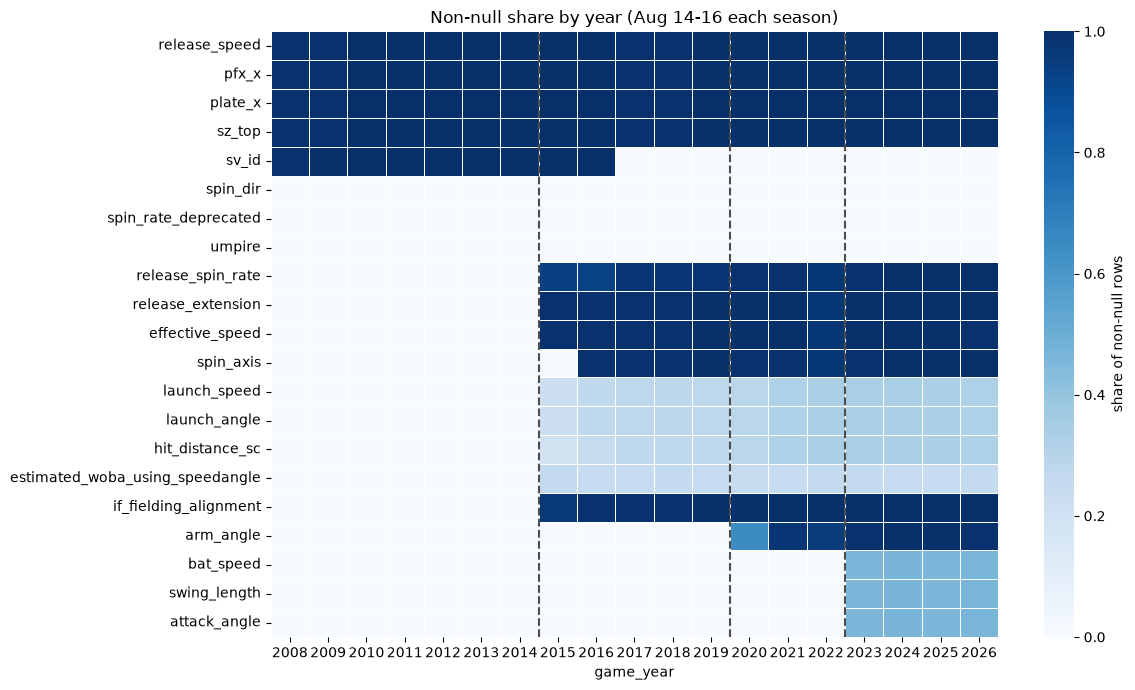

In [11]:
KEY_COLUMNS = [
    'release_speed', 'pfx_x', 'plate_x', 'sz_top', 'sv_id',
    'spin_dir', 'spin_rate_deprecated', 'umpire',
    'release_spin_rate', 'release_extension', 'effective_speed', 'spin_axis',
    'launch_speed', 'launch_angle', 'hit_distance_sc', 'estimated_woba_using_speedangle',
    'if_fielding_alignment', 'arm_angle', 'bat_speed', 'swing_length', 'attack_angle',
]
key_fill = fill.loc[KEY_COLUMNS]

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(key_fill, cmap='Blues', vmin=0, vmax=1, linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'share of non-null rows'}, ax=ax)
for x in [2015, 2020, 2023]:
    ax.axvline(YEARS.index(x), color='0.3', lw=1.5, ls='--')
ax.set_title('Non-null share by year (Aug 14-16 each season)')
ax.set_xlabel('game_year')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [12]:
key_fill.round(2)

game_year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
release_speed,0.99,0.99,1.0,1.0,1.0,1.0,1.0,1.00,1.00,0.99,0.99,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
pfx_x,0.99,0.99,1.0,1.0,1.0,1.0,1.0,1.00,1.00,0.99,0.99,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
plate_x,0.99,0.99,1.0,1.0,1.0,1.0,1.0,1.00,1.00,0.99,0.99,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
sz_top,0.99,0.99,1.0,1.0,1.0,1.0,1.0,1.00,1.00,0.99,0.99,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
sv_id,0.99,1.00,1.0,1.0,1.0,1.0,1.0,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
spin_dir,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
spin_rate_deprecated,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
umpire,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
release_spin_rate,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.94,0.93,0.98,0.98,0.98,0.99,0.99,0.97,0.99,1.00,1.00,1.00
release_extension,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.99,0.99,0.99,0.99,1.00,1.00,1.00,0.97,1.00,1.00,1.00,1.00


### 2-9. 연표와 데이터 대조 (P6)
1-2절의 연표가 실제 데이터의 시작·종료 연도와 맞는지 `assert`로 확인합니다. 이 표본은 매년 8월이므로 "그 해 후반기부터"인 배트 트래킹도 2023년에 채워져 있어야 합니다.

In [13]:
first = summary['first_year']
last = summary['last_year']

# 2008년부터: 투구 추적 컬럼
for c in ['release_speed', 'pfx_x', 'plate_x', 'sz_top', 'vx0', 'ax']:
    assert first[c] == 2008 and last[c] == 2026, c

# 2015년부터: Statcast 도입 후 생긴 타구·회전수·익스텐션 컬럼
for c in ['launch_speed', 'launch_angle', 'hit_distance_sc', 'release_spin_rate', 'release_extension', 'effective_speed']:
    assert first[c] == 2015, c

# 2023년부터: 배트 트래킹
for c in ['bat_speed', 'swing_length']:
    assert first[c] == 2023, c

# 모든 해 비어 있음: 문서에서 폐기 필드로 적힌 컬럼
deprecated = ['spin_dir', 'spin_rate_deprecated', 'break_angle_deprecated', 'break_length_deprecated',
              'tfs_deprecated', 'tfs_zulu_deprecated', 'umpire']
assert (summary.loc[deprecated, 'years_present'] == 0).all()
print('연표 대조 assert 모두 통과')
summary.loc[['release_speed', 'launch_speed', 'release_spin_rate', 'spin_axis', 'arm_angle', 'bat_speed', 'sv_id'],
            ['first_year', 'last_year']]

연표 대조 assert 모두 통과


,first_year,last_year
release_speed,2008,2026
launch_speed,2015,2026
release_spin_rate,2015,2026
spin_axis,2016,2026
arm_angle,2020,2026
bat_speed,2023,2026
sv_id,2008,2016


### 2-10. 인플레이 타구만 놓고 본 타구 컬럼 비결측률
전체 투구 기준 비결측률에는 볼, 스트라이크처럼 타구가 없는 투구가 섞여 있습니다. 문서[1]에서 `type`이 `X`인 투구(인플레이)만 골라 타구 컬럼의 연도별 비결측률을 다시 봅니다.

In [14]:
in_play = sc[sc['type'] == 'X']
bip_fill = (in_play[['launch_speed', 'launch_angle', 'hit_distance_sc', 'hc_x']]
            .notna().groupby(in_play['game_year']).mean())
bip_fill.insert(0, 'balls_in_play', in_play.groupby('game_year').size())
bip_fill.round(3)

,balls_in_play,launch_speed,launch_angle,hit_distance_sc,hc_x
game_year,,,,,
2008,2343,0.000,0.000,0.000,0.928
2009,2480,0.000,0.000,0.000,0.904
2010,2052,0.000,0.000,0.000,0.950
2011,2188,0.000,0.000,0.000,0.952
2012,2171,0.000,0.000,0.000,1.000
2013,2307,0.000,0.000,0.000,1.000
2014,2049,0.000,0.000,0.000,0.999
2015,2471,0.973,0.973,0.868,0.954
2016,2213,0.985,0.985,0.877,0.924


## 3. 결과 해석

**알 수 있는 것**
- 2008~2026년 19개 연도 모두 8월 14~16일에 정규시즌(`R`) 경기가 있었고, 연도마다 36~45경기, 10,847~13,266개 투구가 받아졌습니다.
- 모든 연도의 컬럼은 119개로, 이름과 순서까지 같습니다. 그래서 컬럼 목록만 봐서는 그 해에 측정되었는지 알 수 없고, 비결측률을 봐야 합니다.
- 119개 중 86개는 모든 해에 채워져 있고, 나머지 컬럼의 시작 연도는 1-2절의 연표와 맞습니다.
  - `release_speed`, `pfx_x`, `plate_x` 같은 투구 추적 컬럼은 2008년부터 채워져 있어, 30개 구장에 투구 추적 장비가 설치된 2008년과 맞습니다.
  - `launch_speed`, `launch_angle`, `hit_distance_sc`, `release_spin_rate`, `release_extension` 등 14개 컬럼은 2015년부터 채워져, Statcast가 30개 구장에 설치된 2015년과 맞습니다. 2014년에 시범 운영이 있었다는 기록[2]이 있지만, 이 표본의 2014년에는 값이 없습니다.
  - 배트 트래킹 지표인 `bat_speed`, `swing_length`를 포함한 8개 컬럼은 2023년부터 채워져, 배트 트래킹이 2023년 후반기부터 제공된다는 기록[2][5]과 맞습니다. 2023~2026년 비결측률은 0.46~0.47로, 모든 투구가 아니라 절반에 조금 못 미치는 투구에만 값이 있습니다. 어떤 투구에 값이 있는지는 30회차에서 확인합니다.
  - 문서에서 폐기 필드로 적힌 7개 컬럼(`spin_dir`, `spin_rate_deprecated`, `umpire` 등)은 모든 해에 비어 있습니다.
- 연표로 설명되지 않는 패턴도 있습니다. `sv_id`는 2016년까지만, `spin_axis`는 2016년부터, `arm_angle`은 2020년(비결측률 0.65)부터 채워집니다. 이번 회차에서 확인한 출처로는 이유를 설명할 수 없으므로 관찰 결과로만 기록합니다.
- 인플레이 타구만 보면 `hit_distance_sc` 비결측률은 2015~2019년 86.8~91.8%에서 2020년 이후 98.3% 이상으로 올라갑니다. Hawk-Eye로 바뀐 뒤 추적되는 타구 비율이 약 89%에서 약 99%로 올랐다는 기록[2][4]과 방향이 같습니다.

**주의점**
- 표본은 매년 사흘(8월 14~16일)뿐입니다. 시즌 중간에 시작된 컬럼(예: 2023년 후반기부터인 배트 트래킹)은 8월 표본에 값이 있으므로 "그 해부터"로 보이지만, 정확한 시작 날짜는 이 표본으로 알 수 없습니다.
- 비결측률이 곧 "직접 추적된 비율"은 아닙니다. 문서[1]에 따르면 직접 추적되지 않은 일부 타구의 `launch_speed`, `launch_angle`에는 추정값이 들어갑니다. 그래서 여기서는 `hit_distance_sc`의 변화가 기록과 방향이 같다는 데까지만 말합니다.
- 값이 채워져 있어도 측정 주체가 바뀐 컬럼이 있습니다. `release_speed`는 2008~2026년 내내 채워져 있지만, 2016년까지는 PITCHf/x 값이고 2017년부터는 Statcast 값입니다[1][3]. 비결측률만으로는 이 차이가 보이지 않습니다.
- `woba_value`는 모든 해에 채워져 있지만 `woba_denom`은 2015년부터 채워집니다. 2015년 이전 데이터로 wOBA를 계산할 때 주의해야 합니다(38회차).
- 문서와 실제 컬럼 이름이 다릅니다. 문서의 `release_spin`, `hit_distance`는 실제 데이터에서 `release_spin_rate`, `hit_distance_sc`입니다. 문서에는 z 방향 속도 설명이 `vy0`라는 이름으로 한 번 더 적혀 있고, 실제 데이터의 이름은 `vz0`입니다. 이 스터디에서는 실제 데이터의 이름을 씁니다.

## 4. 요약: 이번 회차에서 알게 된 것
아래는 실행 결과에 근거한 예시 문장입니다. **본인 말로 고쳐 쓰기.**

- pybaseball로 받은 Statcast 데이터는 2008~2026년 모든 해에 같은 119개 컬럼이 있으므로, 그 해에 측정되었는지는 컬럼 목록이 아니라 비결측률로 판단합니다.
- 투구 추적 컬럼은 2008년, 타구·회전수 컬럼은 2015년, 배트 트래킹 컬럼(`bat_speed`, `swing_length`)은 2023년부터 채워져 추적 시스템 연표와 맞습니다.
- `release_speed`처럼 값은 계속 있어도 측정 주체가 바뀐(2017년) 컬럼이 있으므로, 연도를 비교하기 전에 연표를 확인합니다.

## 출처
(2026-10-23 접속)
1. Baseball Savant, Statcast Search CSV Documentation: https://baseballsavant.mlb.com/csv-docs
2. MLB.com Glossary, Statcast: https://www.mlb.com/glossary/statcast
3. MLB.com Glossary, Pitch-tracking Era (since 2008): https://www.mlb.com/glossary/miscellaneous/pitch-tracking-era
4. MLB.com, "What the latest Statcast upgrade makes possible" (2020-09-02): https://www.mlb.com/news/2020-statcast-update-includes-pose-tracking-capabilities
5. Baseball Savant, Bat Tracking Leaderboard: https://baseballsavant.mlb.com/leaderboard/bat-tracking
6. pybaseball `statcast` 함수 docstring (pybaseball 2.2.7)